In [8]:
import argparse
import os
from tqdm import tqdm  
import numpy as np
import torch
import sys

In [ ]:
from uuid import uuid1
import torch as pt
import torch.nn as nn
from torch import ops


import math

import sys
sys.path.append("../../")
from lynadapter.warp_load_save import load,save,load_kernel,save_kernel

class ThreshActRectangleGrad(torch.autograd.Function):
    """
    Threshold activation function with rectangular gradient for training.
    """
    @staticmethod
    def forward(ctx, input, thresh=0.0, approx_region=0.5):
        """
        Forward pass of the threshold activation function.
        
        Args:
            input (torch.Tensor): The input tensor.
            thresh (float): The threshold value.
            approx_region (float): The approximation region for the gradient.
            
        Returns:
            torch.Tensor: The binarized output tensor.
        """
        ctx.save_for_backward(input)
        ctx.thresh = thresh
        ctx.approx_region = approx_region
        bina = torch.gt(input, thresh).to(input.dtype)
        return bina

    @staticmethod
    def backward(ctx, grad_output):
        """
        Backward pass of the threshold activation function.
        
        Args:
            grad_output (torch.Tensor): The gradient of the loss w.r.t. the output.
            
        Returns:
            tuple: The gradient of the loss w.r.t. the input and the parameters.
        """
        input, = ctx.saved_tensors
        thresh = ctx.thresh
        approx_region = ctx.approx_region
        temp = torch.abs(input - thresh) < approx_region
        grad_input = grad_output * temp.to(grad_output.dtype) / (2. * approx_region)
        return grad_input, None, None


spike_func = ThreshActRectangleGrad.apply

MEMB_MODE = (0, pt.relu)
SOMA_PARAMS = {'alpha': .3, 'beta': 0., 'theta': .5, 'v_0': 0., 'shape': [], 'learn': False}


device = pt.device(f'cuda' if pt.cuda.is_available() else 'cpu')

class Lif(nn.Module):
    """
    Leaky Integrate-and-Fire (LIF) neuron model.
    """
    def __init__(self,
                 norm: callable,  # state normalizer
                 mode: str,  # spike | analog
                 memb_mode: tuple,  # (0~3, pt.relu|sigmoid|tanh), valid when ``mode==analog``
                 soma_params: dict,  # {alpha, beta, theta, v_0, shape, learn}
                 noise: float,  # noise scale in training
                 spike_func=None,
                 use_inner_loop=False
                 ):
        super(Lif, self).__init__()
        assert mode in ['spike', 'analog']
        assert len(memb_mode) == 2 and memb_mode[0] in range(4)

        self.norm = norm
        self.mode = mode
        self.memb_mode = memb_mode
        self.use_inner_loop=use_inner_loop
        if spike_func is None:  
            self.spike_func = ThreshActRectangleGrad.apply  
        else:  
            assert callable(spike_func), "spike_func must be a callable function or object."  
            self.spike_func = spike_func   
        shape = soma_params['shape']
        assert isinstance(shape, (list, tuple))
        learn = soma_params['learn']
        func = lambda _: nn.Parameter(pt.randn(shape) if _ is None else (pt.ones(shape) * _), requires_grad=learn)

        self.alpha = func(soma_params['alpha'])
        self.beta = func(soma_params['beta'])
        self.theta = func(soma_params['theta'])
        self.v_0 = func(soma_params['v_0'])
        self.noise = noise
        self.ON_APU = ON_APU
        self.FIT =FIT
        self.MULTINET = False
        self.MODE = 0  
        if self.ON_APU:
            self.id = uuid1()

        self.v = pt.tensor([0]).to(device)
    
    def forward(self, xi: pt.Tensor) -> pt.Tensor:
   
        if hasattr(self, 'id'):  
            if self.MULTINET:
                v = load(self.v.clone(), f'v{self.id}', uselookup=True, mode=self.MODE,init_zero_use_data=xi)
            else:
                v = load(self.v.clone(), f'v{self.id}', mode=self.MODE,init_zero_use_data=xi)
        else:
            v = self.v
     
        # integration
        v = xi + v
        # homeostasis
        if self.norm: v = self.norm(v)
        o1 = v
        if self.training and self.noise > 0:
            self.v = v.clone()
            self.add_noise()
            v=self.v
        o2 = v - self.theta

        if hasattr(self, 'id') and self.FIT:  # XXX for lyngor apu
            # reset & leakage
            self.v = v          
            if self.mode == "spike":
                fire = ops.custom.cmpandfire(self.v.clone(), self.theta)                
                o3 = o4 = v = ops.custom.resetwithdecay(self.v.clone(), self.theta, self.v_0, self.alpha, self.beta)
            else:   
                      
                o3 = v = ops.custom.resetwithdecay(self.v.clone(), self.theta, self.v_0, 1.0, 0.0)
                o4 = v = self.alpha * v + self.beta
        else:     
            # spike firing
            fire = spike_func(o2)
            fire_inv = 1. - fire
            # reset
            o3 = v = fire * self.v_0 + fire_inv * v
            # leakage
            o4 = v = self.alpha * v + self.beta

        if self.mode == 'spike':
            oupt = fire
        else:
            oupt = [o1, o2, o3, o4][self.memb_mode[0]]
            if self.memb_mode[1] is not None:
                oupt = self.memb_mode[1](oupt)        

        self.v = v

        
        if hasattr(self, 'id'):
            if self.MULTINET:
                save(self.v.clone(), f'v{self.id}', uselookup=True, mode=self.MODE)
            else:
                save(self.v.clone(), f'v{self.id}', mode=self.MODE)
        return oupt

    def add_noise(self):
        with pt.no_grad():
            v_shape = self.v.shape
            noise = pt.randn(v_shape, dtype=self.v.dtype, device=self.v.device)
            scale = pt.std(self.v, dim=[_ for _ in range(2, len(v_shape))], keepdim=True) * self.noise
            self.v += noise * scale

    def reset(self, xi):
        self.v = pt.zeros_like(xi)

class FcLif(nn.Module):

    def __init__(self,
                 input_channel: int, hidden_channel: int,
                 feed_back=False, norm_state=True,
                 mode='spike', memb_mode=MEMB_MODE, soma_params='all_share',
                 noise=0,
                 spike_func=None,
                 use_inner_loop=False,
                 it_batch=1
                 ):
        """
            FcLif_step is a fully connected Leaky Integrate-and-Fire (LIF) neuron implementation for a single time step.

            :param input_channel: Number of input channels
            :param hidden_channel: Number of hidden or output channels
            :param feed_back: Whether to use feedback loop (not supported at the moment)
            :param norm_state: Whether to use BatchNorm to prevent gradient explosion, cell state
            :param mode: Discrete spike/continuous membrane potential analog
            :param memb_mode: (0~3, in analog mode, can activate the membrane potential)
            :param soma_params: Specify key parameters of the cell body: alpha, beta, thresh, reset (only support 'all_share' and 'channel_share' now).
                                If necessary, please modify Specify key parameters of the cell body in SOMA_PARAMS.
            :param noise: The level of Gaussian noise within the LIF neuron
            :param spike_func:Specifies the spiking and gradient surrogate function for the LIF neuron; if 'spike_func=None', the default function is used.
        """
        super(FcLif, self).__init__()
        self.use_inner_loop = use_inner_loop
        self.b=it_batch
        self.process_func = self.process_with_inner_loop if self.use_inner_loop==True else self.process_without_inner_loop
        self.p0 = nn.Linear(input_channel, hidden_channel)
        assert feed_back is False, 'Not frequently used, not supported at the moment'

        norm = None
        if norm_state:
            norm = nn.BatchNorm1d(hidden_channel)

        global SOMA_PARAMS
        if soma_params == 'all_share':
            SOMA_PARAMS = SOMA_PARAMS
        elif soma_params == 'channel_share':
            SOMA_PARAMS['shape'] = [1, hidden_channel]
        else:
            raise NotImplementedError

        self.lif = Lif(norm, mode, memb_mode, SOMA_PARAMS, noise,spike_func,use_inner_loop)
    
    def process_with_inner_loop(self, xi):
        x1 = self.p0(xi)       
        x2 = x1.reshape(-1,self.b,x1.shape[-3],x1.shape[-2],x1.shape[-1])
        self.lif.reset(x2[0,...])
            
        xo_list = [self.lif(x2[_,...]) for _ in range(x2.size(0))]
        xos = pt.stack(xo_list, dim=0).reshape(x2.shape[0]*x2.shape[1],x2.shape[2],x2.shape[3],x2.shape[4])  
        return xos
    
    def process_without_inner_loop(self, xi):
        x1 = self.p0(xi)  # projection
        xos = self.lif(x1)  # population
        return xos
    
    def forward(self, xi: pt.Tensor) -> pt.Tensor:
        xos = self.process_func(xi)
        return xos

    def reset(self, xi: pt.Tensor):
        self.lif.v = pt.zeros([xi.size(0), self.p0.out_features], dtype=xi.dtype, device=xi.device,
                              requires_grad=True)



class Conv2dLif(nn.Module):

    def __init__(self,
                 input_channel: int, hidden_channel: int, kernel_size: int, stride=1, padding=0, dilation=1, groups=1,
                 feed_back=False, norm_state=True,
                 mode='spike', memb_mode=MEMB_MODE, soma_params='all_share',
                 noise=0,
                 mp=False,
                 spike_func=None,
                 use_inner_loop=False,
                 it_batch=1
                 ):
        """
        Conv2dLif_step is a convolutional Leaky Integrate-and-Fire (LIF) neuron implementation for a single time step.

        :param input_channel: Number of input channels
        :param hidden_channel: Number of hidden or output channels
        :param feed_back: Whether to use feedback loop (not supported at the moment)
        :param norm_state: Whether to use BatchNorm to prevent gradient explosion, cell state
        :param mode: Discrete spike/continuous membrane potential analog
        :param memb_mode: (0~3, in analog mode, can activate the membrane potential)
        :param soma_params: Specify key parameters of the cell body: alpha, beta, thresh, reset (only support 'all_share' and 'channel_share' now)
                                If necessary, please modify Specify key parameters of the cell body in SOMA_PARAMS
        :param noise: The level of Gaussian noise within the LIF neuron
        :param mp:Determines whether to incorporate a max pooling layer into this layer
        :param spike_func:Specifies the spiking and gradient surrogate function for the LIF neuron; if 'spike_func=None', the default function is used.
        """
        super(Conv2dLif, self).__init__()
        self.use_inner_loop=use_inner_loop
        self.b=it_batch
        self.process_func = self.process_with_inner_loop if self.use_inner_loop==True else self.process_without_inner_loop
        self.p0 = nn.Conv2d(input_channel, hidden_channel, kernel_size, stride=stride, padding=padding,
                            dilation=dilation, groups=groups)
        self.mp = mp
        if self.mp== True:
            self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        else:
            self.pool = nn.Identity()
        assert feed_back is False, 'Not frequently used, not supported at the moment.'

        norm = None
        if norm_state:
            norm = nn.BatchNorm2d(hidden_channel)
            self.norm=nn.Identity()
        else:
            self.norm=nn.BatchNorm2d(hidden_channel)
        global SOMA_PARAMS
        if soma_params == 'all_share':
            SOMA_PARAMS = SOMA_PARAMS
        elif soma_params == 'channel_share':
            SOMA_PARAMS['shape'] = [1, hidden_channel, 1, 1]
        else:
            raise NotImplementedError

        self.lif = Lif(norm, mode, memb_mode, SOMA_PARAMS, noise,spike_func,use_inner_loop)
    
    def process_with_inner_loop(self, xi):
        x1 = self.p0(xi)
        x2 = self.pool(x1)
        x2 = self.norm(x2)
        x3 = x2.reshape(-1, self.b, x2.shape[-3], x2.shape[-2], x2.shape[-1])
        self.lif.reset(x3[0,...])
        
        xo_list = [self.lif(x3[_,...]) for _ in range(x3.size(0))]
        xos = pt.stack(xo_list, dim=0).reshape(x3.shape[0]*x3.shape[1], x3.shape[2], x3.shape[3], x3.shape[4])
        return xos
    
    def process_without_inner_loop(self, xi):
        x1 = self.p0(xi)
        x2 = self.pool(x1)
        x2 = self.norm(x2)
        xos = self.lif(x2)
        return xos
    
    def forward(self, xi: pt.Tensor) -> pt.Tensor:

        xos=self.process_func(xi)

        return xos

    @staticmethod
    def calc_size(h, k, p, s):
        return (h - k + 2 * p) // s + 1

    def reset(self, xi):
        h2, w2 = [self.calc_size(_, self.p0.kernel_size[0], self.p0.padding[0], self.p0.stride[0])
                  for _ in [xi.size(2), xi.size(3)]]
        if self.mp == True:
            self.lif.v = pt.zeros([xi.size(0), self.p0.out_channels,  math.floor((h2 - 2) / 2) + 1, math.floor((w2 - 2) / 2) + 1], dtype=xi.dtype, device=xi.device,
                                    requires_grad=True)  
        else:
            self.lif.v = pt.zeros([xi.size(0), self.p0.out_channels,  h2, w2] , dtype=xi.dtype, device=xi.device,
                                    requires_grad=True)


########################################################################################################################




In [ ]:
from torch.nn import Flatten
class SeqClif3Flif2DgItout(nn.Module):
    """
    Sequential Convolutional LIF - Fully-connected LIF Network for gesture recognition tasks.
    
    Network Architecture:
    - Input -> BatchNorm -> Conv2dLif (x3) -> Flatten -> FcLif (x2) -> Output
    - Contains 3 convolutional LIF layers and 2 fully-connected LIF layers
    - Supports APU deployment and standard GPU/CPU training
    """

    def __init__(self,
                 timestep=60, input_channels=2, h=40, w=40, nclass=11, cmode='spike', fmode='spike', amode='mean', soma_params='all_share', 
                 noise=1e-3, neuron='lif', neuron_config=None,spike_func=None,use_inner_loop=False):
        super(SeqClif3Flif2DgItout, self).__init__()
        neuron = neuron.lower()
        assert neuron in ['lif']
        self.norm = nn.BatchNorm2d(input_channels)
        self.clif1 = Conv2dLif(input_channels, 64, 3, stride=2, padding=1, feed_back=False, mode=cmode, soma_params=soma_params,
                                noise=noise,spike_func=None,use_inner_loop=False)
        self.clif2 = Conv2dLif(64, 128, 3, stride=2, padding=1, feed_back=False, mode=cmode,
                                soma_params=soma_params, noise=noise,spike_func=None,use_inner_loop=False)
        self.clif3 = Conv2dLif(128, 256, 3, stride=2, padding=1, feed_back=False, mode=cmode,
                                soma_params=soma_params, noise=noise,spike_func=None,use_inner_loop=False)
        self.flat = Flatten(1, -1)
        self.flif1 = FcLif(h // 8 * w // 8 * 256, 256, mode=fmode, soma_params=soma_params, noise=noise,spike_func=None,use_inner_loop=False)
        self.flif2 = FcLif(256, nclass, mode=fmode, soma_params=soma_params, noise=noise,spike_func=None,use_inner_loop=False)
        assert amode == 'mean'
        self.tempAdd = None
        self.timestep = timestep
        self.ON_APU = ON_APU
        self.FIT = FIT
     

    def reset(self, xi):
        self.tempAdd = pt.zeros_like(xi)

    def forward(self, xis: pt.Tensor) -> pt.Tensor:
        if self.ON_APU:
            assert len(xis.shape) == 4
            x0 = xis
            x0 = self.norm(x0)
            x1 = self.clif1(x0)
            x2 = self.clif2(x1)
            x3 = self.clif3(x2)
            x4 = self.flat(x3)
            x5 = self.flif1(x4)
            x6 = self.flif2(x5)
            x6 = x6.unsqueeze(2).unsqueeze(3)
     
            
            self.tempAdd = load_kernel(self.tempAdd, f'tempAdd', mode=0,init_zero_use_data=x6)
            self.tempAdd = self.tempAdd + x6 / self.timestep
            output = self.tempAdd.clone()
           
            
            save_kernel(self.tempAdd, f'tempAdd', mode=0)
            return output.squeeze(-1).squeeze(-1)
        else:
            t = xis.size(1)
            xo = 0
            for i in range(t):
                x0 = xis[:, i, ...]
                x0 = self.norm(x0)
                if i == 0: self.clif1.reset(x0)
                x1 = self.clif1(x0)
                if i == 0: self.clif2.reset(x1)
                x2 = self.clif2(x1)
                if i == 0: self.clif3.reset(x2)
                x3 = self.clif3(x2)
                x4 = self.flat(x3)
                if i == 0: self.flif1.reset(x4)
                x5 = self.flif1(x4)
                if i == 0: self.flif2.reset(x5)
                x6 = self.flif2(x5)
                xo = xo + x6 / t

            return xo

In [ ]:
#  load weight and compile
import re
ON_APU= True
FIT = True
LEGACY = False
model = SeqClif3Flif2DgItout(timestep=60, input_channels=2, h=40, w=40, nclass=11, cmode='spike', fmode='spike', amode='mean', noise=0,
        soma_params='all_share', neuron='lif')
in_size = [((1, 2, 40, 40),)]
model_config_path = "../../model_files/classification/Clif3flif2dg_itoutDg"
checkpoint_file_path = "../../weight_files/classification/clif3flif2dg/lif/" + "best_clif3.pth"
state_dict = torch.load(checkpoint_file_path, map_location='cpu')["state_dict"]
new_state_dict1 = {}
new_state_dict2 = {}
new_state_dict3 = {}

for key, value in state_dict.items():
    new_key = re.sub(r'^module\.', '', key, count=1)
    new_state_dict1[new_key] = value
for key, value in new_state_dict1.items():  
    new_key1 = key.replace("backbone.", "")                             
    new_state_dict2[new_key1] = value
for key, value in new_state_dict2.items():  
    new_key2 = key.replace("unit.", "")                             
    new_state_dict3[new_key2] = value
model.load_state_dict(new_state_dict3,strict=False) 
from lynadapter.lyn_compile import model_compile
model_compile(model.eval(),model_config_path,in_size)


/tmp/ipykernel_42998/2960115755.py:10: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(checkpoint_file_path, map_location='cpu')["state_dict"]
pytorch_

lyngor build outpath: ../../model_files/classification/Clif3flif2dg_itoutDg


In [ ]:
#  create dataloader
from datasets.base_dataset import Compose
from datasets.bidl_dvsgesture import DVS128Gesture
from datasets.utils import split_to_train_test_set,TransformedDataset
from torch.utils.data import DataLoader
from functools import partial 
from utils.collate import collate
data_root = os.path.join('../../data', 'DvsGesture')
T = 60
test_compose = Compose([
    dict(type='ResizeDVS', size=40),
    dict(type='ToTensorType', keys=['img'], dtype='float32'), 
])

vis_compose = Compose([
    
    dict(type='ToTensorType', keys=['img'], dtype='float32'), 
])
test_dataset = DVS128Gesture(root=data_root, train=False, data_type='frame', frames_number=T, split_by='number')
vis_dataset = DVS128Gesture(root=data_root, train=False, data_type='frame', frames_number=T, split_by='number')
test_dataset = TransformedDataset(test_dataset.testdata, test_compose)
vis_dataset =  TransformedDataset(vis_dataset.testdata, vis_compose)
classes_num = 11
data_loader = DataLoader(
        test_dataset,
        batch_size=1,
        sampler=None,
        num_workers=1,
        collate_fn=partial(collate, samples_per_gpu=1),
        pin_memory=True,
        shuffle=False,
        drop_last=True
    )
vis_loader = DataLoader(
        vis_dataset,
        batch_size=1,
        sampler=None,
        num_workers=1,
        collate_fn=partial(collate, samples_per_gpu=1),
        pin_memory=True,
        shuffle=False,
        drop_last=True
    )

The frames files [../../data/DvsGesture/frames_number_60_split_by_number/test] already exists and is not empty.
The frames files [../../data/DvsGesture/frames_number_60_split_by_number/test] already exists and is not empty.


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from matplotlib.colors import ListedColormap
import matplotlib

import cv2
from IPython.display import clear_output, display



def simple_frame_by_frame_display(dvs_data, fps=5, loop_count=2):
    """rame-by-frame display"""
    t, _, c, h, w = dvs_data.shape
    
    if c == 2:
        colors = ['black', 'green', 'red', 'white']
        cmap = ListedColormap(colors)
    
    print(f"开始逐帧显示，共{t}帧，循环{loop_count}次")
    
    for loop in range(loop_count):
        print(f"第 {loop+1} 轮播放...")
        
        for frame_idx in range(t):
            clear_output(wait=True)
            
            
            fig, ax = plt.subplots(figsize=(3, 3))
            
            if c == 2:
                pos_events = dvs_data[frame_idx, 0, 0]
                neg_events = dvs_data[frame_idx, 0, 1]
                
                vis_frame = np.zeros((h, w), dtype=np.float32)
                vis_frame[pos_events > 0] = 1
                vis_frame[neg_events > 0] = 2
                #vis_frame[(pos_events > 0) & (neg_events > 0)] = 3
                
                im = ax.imshow(vis_frame, cmap=cmap, vmin=0, vmax=3)
                info = f'step: {frame_idx}/{t-1} '      
  
            
            ax.set_title(f'DVS - {info}')
            ax.set_xlabel('Width')
            ax.set_ylabel('Height')
            
            plt.tight_layout()
            plt.show()            
            
            time.sleep(1.0 / fps)
            
    
    print("播放完成！")

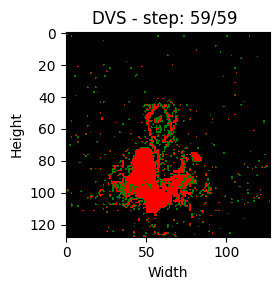

播放完成！
识别结果：滚臂


In [7]:
from lynadapter.lyn_sdk_model import ApuRun
import os
import time

CLASSES = { 0 :"拍手"  ,
            1 :"挥右手",
            2:"其他",
            3 :"挥左手" ,
            4 :"顺时针摆动右臂"   ,
            5 :"逆时针摆动右臂"  ,
            6 :"顺时针摆动左臂"   ,
            7 :"逆时针摆动左臂"   ,
            8 :"滚臂"       ,
            9 :"空气鼓"      ,
            10 :"空气吉他"     ,
            
}

model_path = os.path.join(model_config_path, "Net_0")
chip = 0
apurun = ApuRun(chip, model_path, T)

# Determine data index based on dataset type
idex = 0 

# Measure APU run time
apu_run_time = time.time()
pp_time_cost = 0
pp_per_start = time.time()

data_index =199
# Loop through the data loader
for i, data, vis_data in zip(range(len(data_loader)), data_loader, vis_loader):
    if i== data_index:
    # Preprocess data
        data_img = data[idex].transpose(1, 0).numpy()
        vis_img = vis_data[idex].transpose(1, 0).numpy()
        
        apurun.run(data_img)
        pp_per_start = time.time()
        
        simple_frame_by_frame_display(vis_img, fps=64, loop_count=1)
        
    
    
    
        # Collect APU outputs
        output = apurun.get_output()
        
            
        apu_finish_time = time.time()
        # Process and concatenate outputs
        results = []
        #for i in tqdm(range(len(data_loader))):
            #for c in range(len(chip_id)):
        o = output[0][0][-1]
        o1 = o.reshape(-1, classes_num).argmax()        
        print(f"识别结果：{CLASSES[o1]}")
        break


